```{contents}
:local:
:depth: 2
```

# 2.4 Mixed-Integer Formulations

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 3, Lesson 1: *Linear and Mixed-Integer Linear Formulations* (its lecture comes earlier; read here)
- Module 5, Lesson 1: *MINLP Introduction and Challenges*
- Module 5, Lesson 2: *Mixed-Integer Formulations*

The order here differs on purpose from the videos: the logical operators of Lesson 2 come first, because the fixed-charge model is built from them, and Lesson 1's overview of MINLP and its challenges closes the topic, where it leads into Topics 2.5 and 2.6.
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Translate logical statements (and, or, not, implies, exclusive or) about yes-or-no decisions into linear constraints on binary variables.
- Write the fixed-charge model for equipment that costs something just to be switched on, and explain why it needs a binary variable.
- Choose the big-M constant in an on/off constraint, and explain what goes wrong when it is too large.
- Model a minimum operating load as a semicontinuous variable.
- Explain what makes a mixed-integer nonlinear program (MINLP) hard, and name the main solvers for each problem class.
:::

Up to now every decision in the electrolyzer plant has been a load, which is a number between 0 and 1 that the operator can turn up or down smoothly. However, real plants also make decisions that cannot be made by halves, since a stack either runs or it does not, and a reactor is either built or it is not. We model decisions like these with **binary variables**, which are restricted to the values 0 and 1, and a formulation that mixes them with continuous variables is called **mixed-integer**.

We already met one such problem in Topic 1.2, when the plant had to choose which stacks to switch on. In this topic we will look at how these formulations are written. We will start with the general tool, which translates logic into linear constraints, and then we will use it to build the fixed-charge model of the electrolyzer, leaving the algorithm that solves these problems (branch-and-bound) to Topic 2.5.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import itertools
import numpy as np
import matplotlib.pyplot as plt
import pyomo.environ as pyo
plt.style.use('../settings/plot_style.mplstyle')
from _lib import electrolyzer as el
from _lib import part2b_tools as bt

F = {c: el.F_FIXED[c] for c in el.NAMES}      # fixed charge when on (per-unit power)
e = {c: el.E_LINEAR[c] for c in el.NAMES}     # energy per unit of load (per-unit power)
print("fixed charge F:", F)
print("energy per unit load e:", e)
print(f"1 per-unit of power = {el.MW_PER_UNIT:.3f} MW; 1 unit of load = {el.KG_H_PER_UNIT:.0f} kg H2/h")

fixed charge F: {'A': 0.3, 'B': 0.4, 'C': 0.2}
energy per unit load e: {'A': 1.2, 'B': 1.45, 'C': 1.7}
1 per-unit of power = 6.535 MW; 1 unit of load = 200 kg H2/h


## Logical conditions as linear constraints

A binary variable $y$ can stand for a statement that is either true ($y = 1$) or false ($y = 0$), such as "stack A is running" or "reactor R1 is built". Once the statements are numbers, we can write the logical relations between them as linear inequalities, and since the resulting constraints are linear, the solver never needs to know that they came from logic.

The table below lists the basic operators, and in each row the linear constraint on the right is satisfied by exactly those 0/1 values that make the logical statement on the left true.

| Logical statement | Linear constraint on binaries |
|---|---|
| $P_1$ is true | $y_1 = 1$ |
| NOT $P_1$ | replace $y_1$ by $1 - y_1$ |
| $P_1$ OR $P_2$ (at least one) | $y_1 + y_2 \ge 1$ |
| $P_1$ AND $P_2$ (both) | $y_1 = 1$ and $y_2 = 1$ |
| $P_1$ XOR $P_2$ (exactly one) | $y_1 + y_2 = 1$ |
| at least $m$ / at most $m$ / exactly $m$ of a set $S$ | $\sum_{i \in S} y_i \ge m$, $\le m$, $= m$ |
| $P_1 \Rightarrow P_2$ ($P_1$ implies $P_2$) | $y_1 \le y_2$ |

We will use the implication more than any other operator, so let's check that the translation is correct. The statement "if $P_1$ then $P_2$" is only false when $P_1$ is true and $P_2$ is false, and the constraint $y_1 \le y_2$ rules out exactly that case ($y_1 = 1$ with $y_2 = 0$) while allowing the other three. We can build compound statements by rewriting them with these operators. For example, "if stack A runs, then stack B or stack C must also run" is $y_A \Rightarrow (y_B \text{ OR } y_C)$, which becomes $y_A \le y_B + y_C$, and a plant might impose a rule like this so that a backup stack is always warm when the main one is on.

There are two more compound forms that come up often. The statement "$P_1$ or $P_2$ implies $P_3$" is true unless either premise holds without $P_3$, which means that it becomes two implications, $y_1 \le y_3$ and $y_2 \le y_3$. The statement "($P_1$ or $P_2$) and ($P_3$ or $P_4$)" is just both OR constraints, $y_1 + y_2 \ge 1$ and $y_3 + y_4 \ge 1$, because an AND of statements is just a list of constraints. Choices between groups work in the same way, so "exactly one unit from group $G_1$ or exactly one from group $G_2$, but not units from both" is $\sum_{i \in G_1} y_i = 1 - \sum_{j \in G_2} y_j$ with both sums limited to at most one. For longer statements the systematic route is to rewrite the statement as an AND of ORs (i.e. its conjunctive normal form) and then turn each OR into one inequality.

With three binaries there are only eight cases, so we can check the translation for every case:

In [2]:
def logic(yA, yB, yC):
    """If A runs, then B or C must also run."""
    return (not yA) or bool(yB or yC)

def linear(yA, yB, yC):
    return yA <= yB + yC

print(" yA yB yC | logic  linear")
for yA, yB, yC in itertools.product([0, 1], repeat=3):
    print(f"  {yA}  {yB}  {yC} | {str(logic(yA, yB, yC)):6s} {str(linear(yA, yB, yC)):6s}")
assert all(logic(*y) == linear(*y) for y in itertools.product([0, 1], repeat=3))

 yA yB yC | logic  linear
  0  0  0 | True   True  
  0  0  1 | True   True  
  0  1  0 | True   True  
  0  1  1 | True   True  
  1  0  0 | False  False 
  1  0  1 | True   True  
  1  1  0 | True   True  
  1  1  1 | True   True  


The two columns agree on all eight cases, so the constraint is an exact translation. Logical constraints of this kind show up whenever we choose a design from a **superstructure**, which is a flowsheet that contains every candidate unit and connection with one binary per candidate. The lecture works through examples like this, such as choosing a reactor and then exactly one of two separators if the reactor is chosen. Even though the constraints are linear, the problem is no longer a linear program, because the binaries can only take two values. Formulation is partly an art here, since a cost that jumps (or a choice among alternatives) may look nonlinear, but with the right choice of variables we can make the problem linear.

The same trick also handles non-differentiable terms, often without any binaries. If we want to minimize $|x|$, we can introduce an auxiliary variable $t$ and write $\min t$ subject to $-t \le x \le t$, so that $t = |x|$ at the optimum. A maximum works in the same way. Here $\min \max(f_1, f_2)$ becomes $\min t$ with $t \ge f_1$ and $t \ge f_2$, which is linear whenever the $f_k$ are. This works because these terms are convex and are being minimized, so the solver pushes $t$ down onto the original terms. If we go in the other direction, such as a constraint $|x| \ge 1$, we get a non-convex set ($x \le -1$ or $x \ge 1$) and need a binary to choose the side, which gives $x \ge 1 - M y$ and $x \le -1 + M(1 - y)$.

Logic also links binaries to continuous variables, and this is how the electrolyzer enters the picture. A stack that carries load must be switched on, $x_i > 0 \Rightarrow y_i = 1$, and the fixed-charge model in the next section is built on this one implication.

:::{exercise}
:label: ex-t24-logic

Write linear constraints on $y_A, y_B, y_C$ for each statement, and check each one with a truth-table cell like the one above: (a) "at least two of the three stacks run"; (b) "stack B runs if and only if stack C runs"; (c) "if stack A runs, then neither B nor C runs". Which of the three rules out the plant's optimal configuration found in the next section?
:::

## The fixed-charge model

Suppose that a stack costs something just to be on, whatever its load. Real stacks draw **standby power** to stay hot and pressurized (for pumps, heaters and power electronics that run whether or not much hydrogen is made), and each **start-up** also has a cost, through wear and the time spent heating a cold stack. If we allow only two states (on or off), then we can fold both effects into one number $F_i$ per stack, which is its standby power plus its start-up cost amortized over its typical hours of operation. Studies of real electrolyzer dispatch find that a simple description of this kind is usually adequate (Baumhof et al., 2023), and a model with three states (on, standby, off) is a unit-commitment problem, so we will not consider it here.

The cost of running stack $i$ at load $x_i$ is then

$$
C_i(x_i) = \begin{cases} 0 & x_i = 0 \\ F_i + e_i x_i & 0 < x_i \le 1 \end{cases}
$$

where $e_i$ is the energy per unit of load, as in the dispatch LP of Topic 1.4. This function jumps at zero, so no smooth formula can describe it and no LP can represent it, but a binary variable can. We let $y_i = 1$ mean "stack $i$ is on", so that the cost becomes $F_i y_i + e_i x_i$, and the implication $x_i > 0 \Rightarrow y_i = 1$ is enforced by

$$
x_i \le y_i .
$$

If $y_i = 0$ the load of the stack is pinned to zero, and if $y_i = 1$ the load can be anything up to 1 (the capacity of the stack). The minimizer will never set $y_i = 1$ for an idle stack, since that would only add $F_i$, so the full **fixed-charge dispatch model** is

$$
\begin{aligned}
\min_{x,\,y} \quad & \sum_{i \in \{A,B,C\}} \left( F_i y_i + e_i x_i \right) \\
\text{s.t.} \quad & x_A + x_B + x_C = D \\
& 0 \le x_i \le y_i, \quad y_i \in \{0, 1\} .
\end{aligned}
$$

We will use $F = (0.3, 0.4, 0.2)$ and $e = (1.2, 1.45, 1.7)$ for stacks A, B and C (in per-unit power) and a demand of $D = 1.2$ (240 kg/h). Stack A is the most efficient and B is the next, while C is the least efficient but the cheapest to keep on. The model only takes a few lines in Pyomo, and we will give the builder two extra options now (a big-M constant and a minimum load), since we will need them in the next two sections.

In [3]:
def fixed_charge_model(D, M=1.0, capacity_bound=True, xmin=0.0):
    m = pyo.ConcreteModel()
    m.I = pyo.Set(initialize=el.NAMES)
    m.x = pyo.Var(m.I, bounds=(0, 1) if capacity_bound else (0, None))   # load
    m.y = pyo.Var(m.I, within=pyo.Binary)                                # on/off
    m.demand = pyo.Constraint(expr=sum(m.x[i] for i in m.I) == D)
    m.on_off = pyo.Constraint(m.I, rule=lambda m, i: m.x[i] <= M * m.y[i])
    m.min_load = pyo.Constraint(m.I, rule=lambda m, i: m.x[i] >= xmin * m.y[i])
    m.cost = pyo.Objective(expr=sum(F[i] * m.y[i] + e[i] * m.x[i] for i in m.I))
    return m

solver = pyo.SolverFactory('appsi_highs')
HAVE_HIGHS = solver.available(exception_flag=False)
if not HAVE_HIGHS:
    print("HiGHS is not available through Pyomo; using the book's own branch-and-bound instead.")

def solve_fc(D, M=1.0, capacity_bound=True, xmin=0.0):
    """Solve the fixed-charge model; returns (cost, stacks on, loads)."""
    if HAVE_HIGHS:
        m = fixed_charge_model(D, M, capacity_bound, xmin)
        solver.solve(m)
        x = {i: pyo.value(m.x[i]) + 0.0 for i in el.NAMES}
        cfg = "+".join(i for i in el.NAMES if pyo.value(m.y[i]) > 0.5)
        return pyo.value(m.cost), cfg, x
    if xmin > 0:
        raise RuntimeError("the fallback solver does not model a minimum load")
    cap = 1.0 if capacity_bound else M
    r = bt.fc_bb(list(F.values()), list(e.values()), D, M=[M] * 3, cap=[cap] * 3)
    return r['best'], bt.config(r['z'], 3), dict(zip(el.NAMES, r['z'][:3]))

cost, cfg, x = solve_fc(D=1.2)
print(f"optimum: {cfg} on, loads {', '.join(f'{k} {v:.2f}' for k, v in x.items())}")
print(f"cost {cost:.2f} per-unit = {el.to_mw(cost):.2f} MW")
print("\nall configurations (cost, stacks on, loads):")
for v, c, xs in bt.fc_enumerate(list(F.values()), list(e.values()), 1.2):
    print(f"  {c:6s} " + ("infeasible" if xs is None else f"{v:.2f}  {xs}"))

optimum: A+C on, loads A 1.00, B 0.00, C 0.20
cost 2.04 per-unit = 13.33 MW

all configurations (cost, stacks on, loads):
  A+C    2.04  [1.  0.  0.2]
  A+B    2.19  [1.  0.2 0. ]
  B+C    2.39  [0.  1.  0.2]
  A+B+C  2.39  [1.  0.2 0. ]
  none   infeasible
  C      infeasible
  B      infeasible
  A      infeasible


We can see that the optimum runs A at full load and C at 0.2, for 2.04 per-unit (or 13.33 MW), which is the answer that we found in Topic 1.2. The enumeration confirms that it is unique, since the next best plan (A with B) costs 2.19. C wins over B for the last 0.2 because C is cheap to keep on, and with so little load left the standby cost matters more than the energy cost. In the A+B+C line C is switched on but carries no load, which only adds its fixed charge, and the single-stack configurations are infeasible because one stack cannot make 240 kg/h.

There are two readings of the fixed charge that are worth keeping apart. In thermodynamic terms, $F_i$ is an auxiliary load, which is energy that the stack spends to be ready to split water and which makes no hydrogen.

In economic terms, $F_i$ is a standby cost, which is the price of having the option to produce that is paid whether or not the option is used much, and the binary decides whether that price is worth paying.

:::{exercise}
:label: ex-t24-fixed-charge

Use `solve_fc` to find the optimal configuration for demands $D = 0.6, 0.9, 1.5, 1.8, 2.4$. For which demands does the plant switch configuration, and why? Then lower C's fixed charge to $F_C = 0.1$ (edit the dictionary `F`) and find the smallest demand at which B enters the optimal plan.
:::

## Big-M is the capacity

The on/off constraint is often written in a more general form,

$$
x_i \le M y_i ,
$$

where $M$ is a constant that is called **big-M**. When $y_i = 0$ the constraint pins $x_i$ to zero, as before, and when $y_i = 1$ it caps $x_i$ at $M$. For this to model the logic correctly, $M$ must be a valid upper bound on $x_i$, a value that the load can never exceed. In the electrolyzer this bound is not a free choice, since **the big-M constant is the capacity of the stack**, $M = 1$, which is why we wrote $x_i \le y_i$ above.

Code often picks $M$ as a large round number "to be safe", but this is a poor habit. To see why, remember that a solver works with the **relaxation** of the problem, where each $y_i$ can take any value between 0 and 1 (Topic 2.5 shows how). In the relaxation the cheapest $y_i$ that is consistent with a load $x_i$ is $y_i = x_i / M$, so the cost of the stack becomes

$$
F_i \frac{x_i}{M} + e_i x_i = \left( e_i + \frac{F_i}{M} \right) x_i .
$$

The relaxed model therefore buys a fraction $x_i/M$ of the standby cost of the stack. The larger $M$ is, the smaller that fraction becomes and the more the relaxation underestimates the true cost, which we can see for stack A in the figure below.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


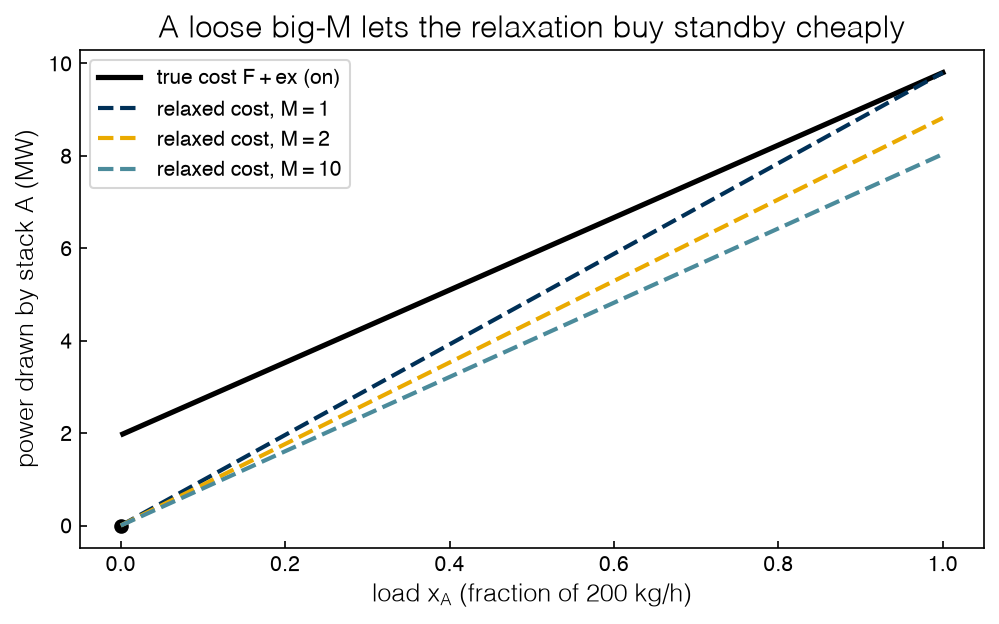

In [4]:
xs = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
true = np.where(xs > 0, F['A'] + e['A'] * xs, 0.0)
ax.plot(xs[1:], el.to_mw(true[1:]), color='k', lw=2.5, label='true cost $F + e x$ (on)')
ax.plot([0], [0], 'ko')
for M in (1, 2, 10):
    ax.plot(xs, el.to_mw((e['A'] + F['A'] / M) * xs), '--', label=f'relaxed cost, $M = {M}$')
ax.set_xlabel('load $x_A$ (fraction of 200 kg/h)')
ax.set_ylabel('power drawn by stack A (MW)')
ax.set_title('A loose big-M lets the relaxation buy standby cheaply')
ax.legend();

With $M = 1$ we get the tightest possible relaxed cost, which is the line from the origin to the true cost at full load (Topic 2.6 calls this the convex envelope). With $M = 10$, on the other hand, the relaxed cost lies close to the bare energy cost $e_A x_A$, and almost none of the standby charge is left in the relaxed cost.

:::{admonition} Warning: a loose big-M weakens the bound, and can change the answer
:class: warning

The table below the box solves the plant with $M = k$ for $k = 1, 2, 5, 10$, in two ways. In the first, the capacity $x_i \le 1$ is kept as a separate bound. In the second, it is dropped, so that $M$ alone limits each load.

- **Mechanism.** With a fractional $y$ in the relaxation, a large $M$ lets the model buy load for a small fraction of the standby cost. The relaxation cheats, and its value, the bound, gets weaker.
- **If the capacity is enforced elsewhere, the answer is the same but the bound is weaker.** The root bound falls from 1.87 at $M = 1$ to 1.68, 1.566 and 1.528. The optimum stays 2.04. Branch-and-bound (Topic 2.5) needs 9 nodes instead of 7 to prove it, so the weaker bound costs work.
- **If it is not, the answer is wrong.** Without the separate capacity bound, every $k \ge 2$ returns 1.74 with stack A alone carrying 1.2, more than it can make. Here $M$ *is* the capacity in the model, and we have told the model that the stack is bigger than it is.
- **Discipline.** Use the tightest valid bound. In a physical model it is a real engineering quantity, here a capacity, not a round number like $10^6$.
:::

In [5]:
Fl, El = list(F.values()), list(e.values())
print(" k | capacity kept: root bound  optimum  nodes | no capacity bound: root bound  optimum  loads")
for k in (1, 2, 5, 10):
    row = []
    for keep in (True, False):
        Mk, cap = [float(k)] * 3, [1.0] * 3 if keep else [float(k)] * 3
        _, root = bt.fc_lp(np.array(Fl), np.array(El), 1.2, Mk, [(0, c) for c in cap] + [(0, 1)] * 3)
        res = bt.fc_bb(Fl, El, 1.2, M=Mk, cap=cap)
        loads = ", ".join(f"{n} {v:.1f}" for n, v in zip(el.NAMES, res['z'][:3]) if v > 1e-9)
        row.append((root, res['best'], res['nodes'], loads))
    (r1, b1, n1, _), (r2, b2, _, l2) = row
    print(f"{k:2d} |      {r1:.3f}          {b1:.2f}     {n1}   |      {r2:.3f}          {b2:.2f}    {l2}")

 k | capacity kept: root bound  optimum  nodes | no capacity bound: root bound  optimum  loads
 1 |      1.870          2.04     7   |      1.870          2.04    A 1.0, C 0.2
 2 |      1.680          2.04     9   |      1.620          1.74    A 1.2
 5 |      1.566          2.04     9   |      1.512          1.74    A 1.2
10 |      1.528          2.04     9   |      1.476          1.74    A 1.2


The root bound is the value of the relaxation with no binary fixed, and it is the bound that branch-and-bound starts from. The right half of the table is the dangerous one, because there is nothing in the output to warn the user. In each of those cases the solver still reports an optimal solution to the model as written, but the model itself is wrong.

:::{exercise}
:label: ex-t24-bigm

Give each stack its own big-M, $M = (1, 1, 5)$ for A, B and C, with no separate capacity bound. Before running anything, predict the optimal plan at $D = 1.2$; then check your prediction with `bt.fc_bb`. Which stack is "enlarged" by the error, and does the error change the plan at $D = 1.2$? At $D = 2.4$?
:::

## Minimum load and semicontinuous variables

A real stack cannot run at every load from 0 to 1. Below a minimum load the gas purity becomes unsafe and the stack must be shut down. For the alkaline stacks modeled by Baumhof et al. (2023) this minimum is about 15% of rated load (7.84 MW for their 52.25 MW stack). This means that the load must either be zero or lie in the range from $x_{\min}$ to 1, with no load allowed between zero and $x_{\min}$, and a variable of this kind is called **semicontinuous**. We can write this condition with the same binary:

$$
x_{\min} y_i \le x_i \le y_i .
$$

When $y_i = 0$ both sides are zero, and when $y_i = 1$ the load lies in $[x_{\min}, 1]$. In this book we use the stylized value $x_{\min} = 0.1$ (20 kg/h per stack), which does not bind at $D = 1.2$ (where C already runs at 0.2) but does bind at a demand of $D = 1.05$ (210 kg/h).

In [6]:
for D in (1.2, 1.05):
    for xmin in (0.0, el.X_MIN):
        if xmin > 0 and not HAVE_HIGHS:
            print("skipping the minimum-load case: it needs HiGHS"); continue
        cost, cfg, x = solve_fc(D=D, xmin=xmin)
        loads = ", ".join(f"{k} {v:.2f}" for k, v in x.items() if v > 1e-9)
        print(f"D = {D:.2f} ({el.to_kg_h(D):.0f} kg/h), x_min = {xmin:.1f}: {cfg:4s} loads {loads:16s} "
              f"cost {cost:.3f} = {el.to_mw(cost):.2f} MW")

D = 1.20 (240 kg/h), x_min = 0.0: A+C  loads A 1.00, C 0.20   cost 2.040 = 13.33 MW


D = 1.20 (240 kg/h), x_min = 0.1: A+C  loads A 1.00, C 0.20   cost 2.040 = 13.33 MW


D = 1.05 (210 kg/h), x_min = 0.0: A+C  loads A 1.00, C 0.05   cost 1.785 = 11.67 MW


D = 1.05 (210 kg/h), x_min = 0.1: A+C  loads A 0.95, C 0.10   cost 1.810 = 11.83 MW


Without a minimum load the optimal plan at $D = 1.05$ runs A at full load and C at 0.05, for 1.785. With $x_{\min} = 0.1$ C is not allowed to run that low, so the plan keeps the same stacks but moves load from A to C (with A at 0.95 and C at 0.10), for 1.810. The configuration is the same and only the loads have moved, because the cheapest way to meet the minimum on C is to back A off.

Minimum loads can also make some configurations infeasible, because $k$ running stacks cannot meet a demand that is below $k\,x_{\min}$.

:::{exercise}
:label: ex-t24-xmin

Sweep the demand from $D = 1.0$ to $1.2$ in steps of $0.01$ with $x_{\min} = 0.1$, and plot the optimal cost (in MW) and the load on C against demand in kg/h. Over what range of demand does the minimum load bind? Then raise $x_{\min}$ to $0.3$. Does the optimal configuration change anywhere in that range?
:::

## General integer variables

Binaries are a special case of **integer variables**, which can take any whole-number value in a range. We can use these to model counts and discrete sizes, such as the number of identical units to run, the number of trucks to send, or the number of fixed-size batches that a unit produces. The blending example in the lecture is of this kind, since production is made in whole batches of a fixed size, so the amount produced is the batch size times an integer (that example also has a nonlinear revenue, which makes it an MINLP).

For the electrolyzer, let's suppose that the plant has up to three identical stacks of type A and up to three of type C. Since it only matters how many of each type run (and not which ones), we can replace the per-stack binaries by integer counts $n_A, n_C \in \{0, 1, 2, 3\}$ and the per-stack loads by the total load $X_t$ that is carried by each type:

$$
\min \ \sum_{t \in \{A, C\}} \left( F_t n_t + e_t X_t \right) \quad \text{s.t.} \quad X_A + X_C = D, \quad 0 \le X_t \le n_t, \quad n_t \in \{0, 1, 2, 3\} .
$$

The coupling $X_t \le n_t$ is just the big-M constraint again, with $M = 1$ per running stack. Using one integer instead of three binaries per type also removes **symmetry**, because with binaries the plans "stacks 1 and 2 on" and "stacks 2 and 3 on" are different solutions with the same cost, and a solver would waste effort telling them apart.

In [7]:
def count_model(D, relax=False):
    m = pyo.ConcreteModel()
    m.T = pyo.Set(initialize=['A', 'C'])
    m.n = pyo.Var(m.T, within=pyo.NonNegativeReals if relax else pyo.NonNegativeIntegers, bounds=(0, 3))
    m.X = pyo.Var(m.T, bounds=(0, None))
    m.demand = pyo.Constraint(expr=sum(m.X[t] for t in m.T) == D)
    m.cap = pyo.Constraint(m.T, rule=lambda m, t: m.X[t] <= m.n[t])
    m.cost = pyo.Objective(expr=sum(F[t] * m.n[t] + e[t] * m.X[t] for t in m.T))
    return m

if HAVE_HIGHS:
    for D in (2.4, 3.3):
        for relax in (True, False):
            m = count_model(D, relax)
            solver.solve(m)
            plan = ", ".join(f"n_{t} = {pyo.value(m.n[t]) + 0:.2f} (load {pyo.value(m.X[t]) + 0:.2f})" for t in m.T)
            print(f"D = {D} ({el.to_kg_h(D):.0f} kg/h), {'relaxed' if relax else 'integer'}: {plan}; cost {pyo.value(m.cost):.2f}")
else:
    print("HiGHS is not available; this cell needs an MILP solver.")

D = 2.4 (480 kg/h), relaxed: n_A = 2.40 (load 2.40), n_C = 0.00 (load 0.00); cost 3.60


D = 2.4 (480 kg/h), integer: n_A = 3.00 (load 2.40), n_C = 0.00 (load 0.00); cost 3.78


D = 3.3 (660 kg/h), relaxed: n_A = 3.00 (load 3.00), n_C = 0.30 (load 0.30); cost 5.07


D = 3.3 (660 kg/h), integer: n_A = 3.00 (load 3.00), n_C = 1.00 (load 0.30); cost 5.21


At 480 kg/h ($D = 2.4$) the relaxation runs 2.4 stacks of type A (which no plant can do) for 3.60. If we round down to two A stacks we cannot meet the demand, and the integer optimum runs three A stacks, partly loaded, for 3.78. At 660 kg/h ($D = 3.3$) all three A stacks run at full load and one C stack takes the last 0.3, for 5.21. As with binaries, the value of the relaxation is a lower bound but its fractional counts are not a plan.

A bounded integer can also be written with binaries by **binary expansion**, so that $n = y_1 + 2 y_2$ covers $n = 0, \ldots, 3$. One thing that a MILP may *not* contain is a product of variables, such as a load times an on/off binary written as $x y$, because that product is nonlinear, and we will see how bilinear terms like this are handled in Topic 2.6.

:::{exercise}
:label: ex-t24-integers

Add stack type B to `count_model` (up to three B stacks) and find the optimal counts for demands from 0.6 to 6.0 in steps of 0.6. At which demands does the relaxation's value equal the integer optimum? Then rewrite $n_A$ by binary expansion with two binaries and confirm that the optimum does not change.
:::

## From MILP to MINLP: why mixed-integer problems are hard

Everything so far has been linear in the variables, so the fixed-charge model is a **mixed-integer linear program** (MILP). MILPs are everywhere in engineering and operations, including production planning and scheduling, supply chains, network flows, unit commitment in power grids, the selection of units in a flowsheet, and combinatorial problems such as knapsack packing, assignment of people to tasks, and protein design. Many practical MILPs can now be solved routinely at large scale as a result of decades of algorithmic progress on top of the simplex method (Topic 1.5) and of faster computers, and commercial solvers such as Gurobi and CPLEX (and open-source ones such as HiGHS and CBC) solve problems with thousands of binary variables in seconds. HiGHS is the solver behind `scipy.optimize.milp` and the `appsi_highs` interface that we used above. The COIN-OR project hosts many open-source solvers, and independent benchmarks (such as those maintained by Hans Mittelmann at Arizona State University) compare LP and MILP solvers on problems with millions of variables.

If any function in the model is nonlinear, then the problem is a **mixed-integer nonlinear program** (MINLP). Most of the problems that MILPs approximate become MINLPs once the unit models are made more detailed, so a flowsheet synthesis problem with real reactor and separator models is an MINLP, and so is a production plan with nonlinear yields. The same is true for the design of water distribution networks, multiproduct batch scheduling, and an optimization problem with a trained machine-learning model embedded in it (such as a ReLU neural network or a regression tree), and models of this last kind appear later in the book.

MINLPs are the hardest class of problems in this book, and there are three reasons for this that compound each other:

1. **Combinatorics.** Each assignment of the binaries defines its own continuous subproblem. With $n$ binaries there are $2^n$ of them. Three stacks give 8; thirty stacks give more than a billion.
2. **Nonlinearity.** Each subproblem is an NLP, not an LP. If the NLP is non-convex, a local solver may stop at a point that is not its best (Topic 1.1).
3. **Fewer and weaker tools.** Solvers that handle both difficulties exist, but there are fewer of them, they are slower, and the best are commercial.

The useful distinction is between convex and non-convex MINLPs. An MINLP is **convex** if its continuous relaxation (i.e. the problem with each binary allowed anywhere in $[0, 1]$) is a convex NLP. There are exact methods for convex MINLPs that need no spatial branching, whereas non-convex ones need the spatial branch-and-bound of Topic 2.6 for a proof. The solvers that are named in the lecture, along with two more, sort out as follows:

- **DICOPT** (commercial, GAMS): outer approximation, alternating MILP master problems and NLP subproblems; exact on convex MINLPs, a heuristic on non-convex ones.
- **Bonmin** (open source): NLP-based branch-and-bound or outer approximation with Ipopt; the same verdict as DICOPT.
- **BARON** (commercial): global; spatial branch-and-bound with convex relaxations, range reduction and heuristics.
- **ANTIGONE** (commercial, GAMS): global; reformulation, convex relaxations and spatial branch-and-bound.
- **Couenne** (open source): global; spatial branch-and-bound on linear relaxations of the non-convex terms.
- **SCIP** (open source): global for MINLP; spatial branch-and-bound for non-convex terms, built on a MILP branch-and-cut (constraint integer programming) framework.

MILPs are served by HiGHS and CBC (which are open source) and by Gurobi and CPLEX (which are commercial). If we run a local MINLP method on a non-convex problem it will still report its answer as optimal, which is the trap that Topic 2.6 sets out to show.

There are two structural ideas that run through all MINLP algorithms. The first is **decomposition**, which uses the fact that once the integer variables are fixed, what remains is a continuous problem that is often linear, quadratic or convex and therefore easy, so many methods alternate between choosing integers (a MILP "master" problem) and solving the continuous subproblem (outer approximation and generalized Benders decomposition work this way). The second is **convexification**, where non-convex terms are bounded above and below by simpler convex functions, which gives easy problems whose solutions bound the original. Branch-and-bound (Topics 2.5 and 2.6) is built on the second idea.

:::{exercise}
:label: ex-t24-count

Compute $2^{30}$ and $2^{40}$. If each continuous subproblem took one millisecond to solve, how long would complete enumeration take for a plant with 30 stacks, and for 40? What does this tell you about the need for an algorithm that avoids solving most subproblems?
:::

## A preview: the S-shaped power curve

The fixed charge treats the standby cost of a stack as a jump at zero load, whereas physically the loss comes on over a short range of low loads rather than all at once. At low current a noticeable fraction of the current in an alkaline stack does not make hydrogen, because some current leaks around the cells and some gas crosses the separator and recombines. This is a drop in the **Faraday efficiency**, the fraction of the current that ends up as hydrogen, and it makes the power needed per kilogram rise sharply at low load (Ulleberg, 2003; Sánchez et al., 2018).

The book's model of this effect is the S-shaped curve of Topic 1.1,

$$
P_i(x) = x + a_i \frac{x}{x + \epsilon} + r_i x^2 ,
$$

where the first term is the ideal energy, the last is the convex ohmic loss of Topic 2.1, and the middle term is a **smoothed fixed charge**, an auxiliary load of size $a_i$ that ramps in over a short start-up range of width about $\epsilon$. This middle term is concave, and with $\epsilon = 0.05$ the whole curve bends the wrong way below about a quarter of full load. Its sizes $a = (0.3, 0.4, 0.2)$ equal the fixed charges $F$ above, on purpose.

Our curve exaggerates the effect. In real alkaline stacks the concave region lies below the minimum load, so **real stacks are convex over the range they are allowed to run** (Baumhof et al., 2023). We keep the concave region inside the operating range because it is the simplest way to show what non-convexity does to optimization. The figure compares the three stacks' S-curves, and shows stack A's curve approaching the fixed-charge step as $\epsilon$ shrinks.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


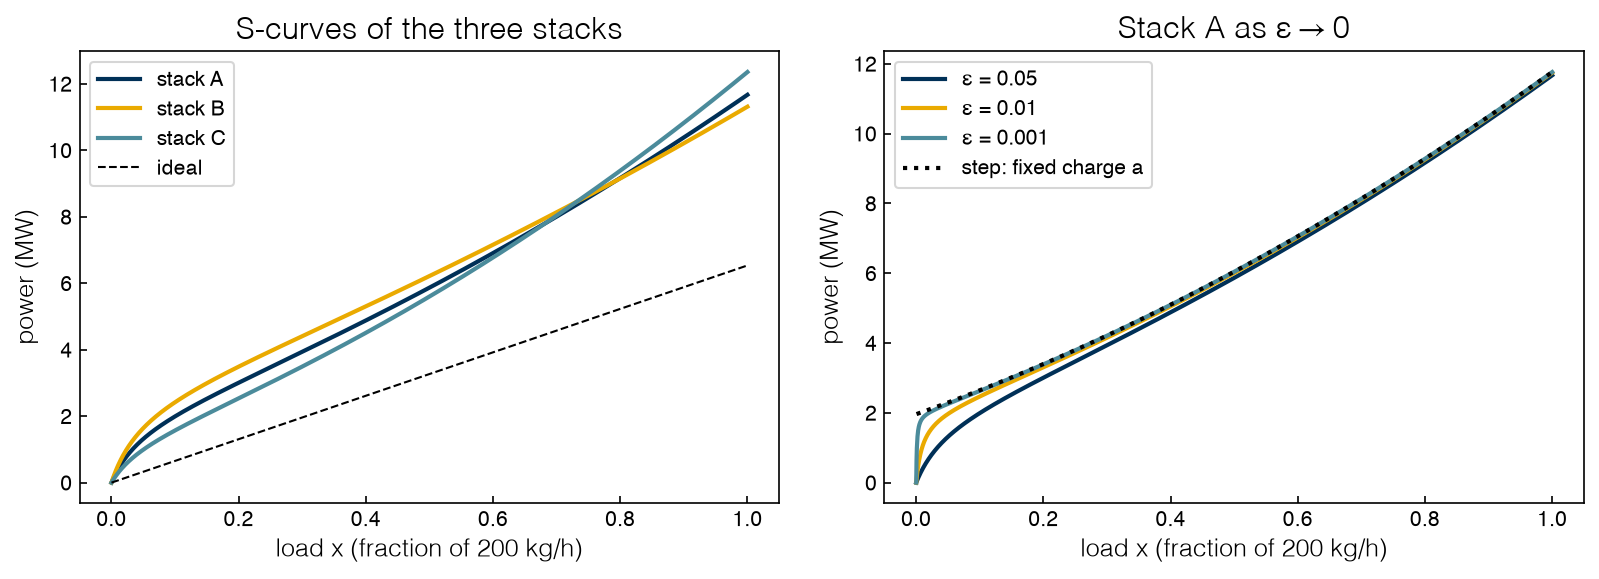

In [8]:
x = np.linspace(0, 1, 2001)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for c in el.NAMES:
    axes[0].plot(x, el.to_mw(el.p_scurve(x, c)), label=f'stack {c}')
axes[0].plot(x, el.to_mw(x), 'k--', lw=1, label='ideal')
axes[0].set_title('S-curves of the three stacks')
a, r = el.A_PARASITIC['A'], el.R_OHMIC['A']
for eps in (0.05, 0.01, 0.001):
    axes[1].plot(x, el.to_mw(x + a * x / (x + eps) + r * x**2), label=f'$\\epsilon$ = {eps}')
axes[1].plot(x[1:], el.to_mw(x[1:] + a + r * x[1:]**2), 'k:', lw=2, label='step: fixed charge $a$')
axes[1].set_title('Stack A as $\\epsilon \\to 0$')
for ax in axes:
    ax.set_xlabel('load $x$ (fraction of 200 kg/h)')
    ax.set_ylabel('power (MW)')
    ax.legend()
plt.tight_layout()

As $\epsilon \to 0$ the smoothed charge becomes a step of height $a$ at zero load, which is a fixed charge. Topic 2.6 shows that the fixed-charge model of this topic is exactly this limit with the remaining losses linearized. A binary variable therefore represents an infinitely sharp concave cost exactly, and the curve with $\epsilon = 0.05$ is a smoothed version of the same difficulty.

If we put the S-curve together with on/off binaries, a fixed on-cost $F_{\text{on}}$ and a minimum load, then the plant becomes a non-convex MINLP:

$$
\begin{aligned}
\min_{x,\,y} \quad & \sum_i \left[ F_{\text{on}}\, y_i + P_i(x_i) \right] \\
\text{s.t.} \quad & \sum_i x_i = D, \qquad x_{\min} y_i \le x_i \le y_i, \qquad y_i \in \{0, 1\} .
\end{aligned}
$$

This problem has every difficulty from the list in the previous section. In Topic 2.5 we will develop branch-and-bound on the linear version, where every bound can be trusted, and in Topic 2.6 we will solve this one with a certificate of global optimality.

:::{exercise}
:label: ex-t24-scurve

For stack A, compute the specific energy $P_A(x)/x$ on a grid of loads, and convert it to kWh per kg of hydrogen using `el.MW_PER_UNIT` and `el.KG_H_PER_UNIT`. At what load is the specific energy smallest? Repeat with $\epsilon = 0.001$. How does the most efficient load move as the start-up range narrows?
:::

## Summary

- Binary variables turn yes-or-no decisions into numbers. Logical relations (and, or, not, implies, exclusive or) become linear constraints on them; an implication $P_1 \Rightarrow P_2$ is $y_1 \le y_2$.
- The fixed-charge model represents a cost that jumps at zero, such as a stack's standby power plus amortized start-up. Its on/off constraint $x_i \le M y_i$ is the implication $x_i > 0 \Rightarrow y_i = 1$.
- Big-M must be a valid upper bound, and in a physical model it is the capacity. A loose M weakens the relaxation's bound (1.87 down to 1.528 here) and costs branch-and-bound nodes; without a separate capacity bound it gives a wrong answer (1.74, with one stack over capacity).
- A minimum load makes a variable semicontinuous, $x_{\min} y_i \le x_i \le y_i$.
- MINLPs combine combinatorial and nonlinear difficulty. Convex MINLPs have exact methods; non-convex MINLPs need global (spatial) branch-and-bound. The electrolyzer's S-shaped curve, a stated exaggeration of a real Faraday-efficiency effect, makes the plant a non-convex MINLP.

## Additional Reading

- Hart, W. E., Laird, C. D., Watson, J.-P., Woodruff, D. L., Hackebeil, G. A., Nicholson, B. L., and Siirola, J. D. *Pyomo — Optimization Modeling in Python*, 3rd ed. Springer, 2021.
- Williams, H. P. *Model Building in Mathematical Programming*, 5th ed. Wiley, 2013. The standard reference for logical conditions, fixed charges and big-M formulations.
- Floudas, C. A. *Nonlinear and Mixed-Integer Optimization: Fundamentals and Applications*. Oxford University Press, 1995.
- Grossmann, I. E. *Advanced Optimization for Process Systems Engineering*. Cambridge University Press, 2021.
- Ulleberg, Ø. Modeling of advanced alkaline electrolyzers: a system simulation approach. *International Journal of Hydrogen Energy* 28, 21–33 (2003).
- Sánchez, M., Amores, E., Rodríguez, L., and Clemente-Jul, C. Semi-empirical model and experimental validation for the performance evaluation of a 15 kW alkaline water electrolyzer. *International Journal of Hydrogen Energy* 43, 20332–20345 (2018).
- Baumhof, M. T., Raheli, E., Johnsen, A. G., and Kazempour, J. Optimization of hybrid power plants: when is a detailed electrolyzer model necessary? arXiv:2301.05310 (2023). With the two papers above, the electrolyzer models that inspired the book's S-curve and on/off description.